In this notebook we will compare the predictions from MW11 model with the actual ASTRID measurements of P1D and Px. For that reason the model predictions will be computed using ASTRID cosmology and cddf.

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from forestflow import pcross

import sys
import os
sys.path.append(os.path.abspath(".."))
from model import p3d_model, p1d_model, _p3d_internal, px_model
from utils import cddf_to_fNHiX, Cosmologies

In [2]:
# ASTRID cosmology, for example
cosmo = Cosmologies().get_cosmo(name='ASTRID')
bias_hcd, bias_lya = 2, -0.14
z = 2.5

In [3]:
data_on = '/data/desi/scratch/lfloresl/ASTRID/ASTRID/data/spectra_ASTRID_z2.5_500x500x2500.hdf5'  # With self-shielding

with h5py.File(data_on, 'r') as f:
    print('Keys:', f.keys())
    header_on = f['Header']
    print('------ Header ------')
    for attr in header_on.attrs:
            print(f"{attr} : {header_on.attrs[attr]}")
    print('------ Data ------')
    colden = f['colden/H/1'][:]
    print('colden shape:', colden.shape)

    Lbox = 250  # Mpc/h
    Nsk = int(np.sqrt(colden.shape[0]))  # colden.on_shape[0] gives the size of the axis

Keys: <KeysViewHDF5 ['Header', 'colden', 'spectra', 'tau']>
------ Header ------
Hz : 252.87249366801257
box : 250000.0
discarded : 0
hubble : 0.6774
nbins : 2500
npart : [165988309584 166375000000            0            0  10297622146
     11325619]
omegab : 0.0486
omegal : 0.6911
omegam : 0.3089
redshift : 2.499999947500001
------ Data ------
colden shape: (250000, 2500)


In [4]:
NHirange = np.linspace(17.2, 21.3) 
colden_log = np.log10(colden[colden > 0])
fNHiX = cddf_to_fNHiX(colden_log, NHirange, Lbox, Nsk, z)
del colden, colden_log

# P3D 

In [5]:
results_3d = p3d_model(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX)
k = results_3d['k']
mu = results_3d['mu']
p3d_tot = results_3d['p3d_tot']
p3d_lya = results_3d['p3d_lya']
p3d_hcd = results_3d['p3d_hcd']
p3d_lyahcd = results_3d['p3d_lyahcd']

# P1D

In [6]:
results_1d = p1d_model(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX)
w1 = _p3d_internal(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX)['w1']
k_los_m = results_1d['k_los']
p1d_tot = results_1d['p1d_tot']
p1d_lya = results_1d['p1d_lya']
p1d_hcd = results_1d['p1d_hcd']
p1d_lyahcd = results_1d['p1d_lyahcd']

In [7]:
data = '/data/desi/scratch/lfloresl/astrid_hcd_outputs/p1ds_0.3_21.3.hdf5'

with h5py.File(data, 'r') as f:
    print('Atributes:')
    for m in f.attrs.keys():
        print(f'{m} = {f.attrs[m]}')
    print('----------------') 
    print('Data:')
    print(f.keys())
    k_los = f['k_los'][1:]
    print('k_los shape:', k_los.shape)
    p1ds_tot = f['p1d_tot'][:, 1:]
    print('p1ds_tot shape:', p1ds_tot.shape)
    p1ds_lya = f['p1d_lya'][:, 1:]
    print('p1ds_lya shape:', p1ds_lya.shape)
    p1ds_hcd = f['p1d_hcd'][:, 1:]
    print('p1ds_hcd shape:', p1ds_hcd.shape)
    p1ds_lyahcd = f['p1d_lyahcd'][:, 1:]
    print('p1ds_lyahcd shape:', p1ds_lyahcd.shape)
    Cs = f['C'][()]
    print('Cs shape = ', Cs.shape)
    mask = f['mask'][:]
    print('mask shape:', mask.shape)

Atributes:
Smoothing factor = 0.3
logNHI_max = 21.3
logNHI_min = 0
minibox_size_Mpch = 250
pixel_width_Mpch = 0.1
pixels_per_skewer = 2500
skewer_separation_Mpch = 0.5
skewers_per_side = 100
----------------
Data:
<KeysViewHDF5 ['C', 'k_los', 'mask', 'p1d_3hcd', 'p1d_3lya', 'p1d_4', 'p1d_hcd', 'p1d_lya', 'p1d_lyahcd', 'p1d_tot']>
k_los shape: (1250,)
p1ds_tot shape: (25, 1250)
p1ds_lya shape: (25, 1250)
p1ds_hcd shape: (25, 1250)
p1ds_lyahcd shape: (25, 1250)
Cs shape =  (25,)
mask shape: (10000,)


WARNING: p1ds are in Mpc/h units and k_los in h/Mpc

In [8]:
k_los *= cosmo.CAMBparams.h  # In Mpc^-1
p1ds_tot /= cosmo.CAMBparams.h
p1ds_lya /= cosmo.CAMBparams.h
p1ds_hcd /= cosmo.CAMBparams.h
p1ds_lyahcd /= cosmo.CAMBparams.h

p1d_tot_m = np.interp(k_los, k_los_m, p1d_tot)
p1d_lya_m = np.interp(k_los, k_los_m, p1d_lya)
p1d_hcd_m = np.interp(k_los, k_los_m, p1d_hcd)
p1d_lyahcd_m = np.interp(k_los, k_los_m, p1d_lyahcd)
w1_m = np.interp(k_los, k_los_m, w1)

In [9]:
Nmodes = p1ds_tot.shape[0]
P1d_tot, P1d_std_tot = np.mean(p1ds_tot, axis=0), np.std(p1ds_tot, axis=0)/np.sqrt(Nmodes-1)
P1d_lya, P1d_std_lya = np.mean(p1ds_lya, axis=0), np.std(p1ds_lya, axis=0)/np.sqrt(Nmodes-1)
P1d_hcd, P1d_std_hcd = np.mean(p1ds_hcd, axis=0), np.std(p1ds_hcd, axis=0)/np.sqrt(Nmodes-1)
P1d_lyahcd, P1d_std_lyahcd = np.mean(p1ds_lyahcd, axis=0), np.std(p1ds_lyahcd, axis=0)/np.sqrt(Nmodes-1)

/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/collections.py:1528: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[:n, 0], pts[:n, 1] = t_where, f1_where
/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/collections.py:1529: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[n:, 0], pts[n:, 1] = t_where, f2_where
/data/desi/scratch/lfloresl/hcd_env/lib/python3.12/site-packages/matplotlib/collections.py:1592: ComplexWarning: Casting complex values to real discards the imaginary part
 

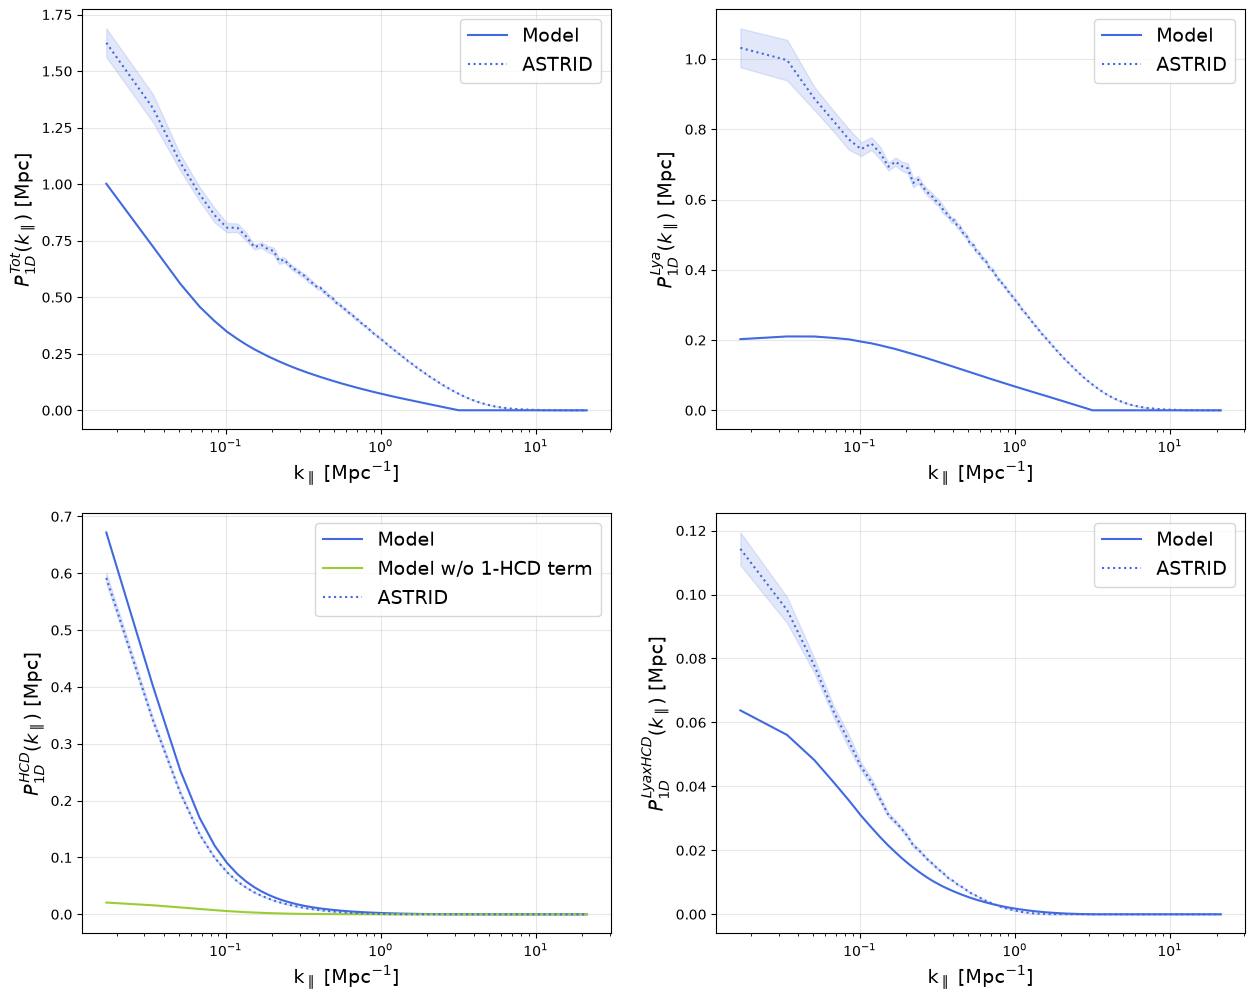

In [10]:
plt.figure(figsize=(15, 12))

plt.subplot(2, 2, 1)
plt.plot(k_los, p1d_tot_m, color='royalblue', label='Model')
plt.plot(k_los, P1d_tot, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_tot-P1d_std_tot), (P1d_tot+P1d_std_tot), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{Tot}(k_\parallel)$ [Mpc]', fontsize=14)


plt.subplot(2, 2, 2)
plt.plot(k_los, p1d_lya_m, color='royalblue', label='Model')
plt.plot(k_los, P1d_lya, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_lya-P1d_std_lya), (P1d_lya+P1d_std_lya), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{Lya}(k_\parallel)$ [Mpc]', fontsize=14)


plt.subplot(2, 2, 3)
plt.plot(k_los, p1d_hcd_m, color='royalblue', label='Model')
plt.plot(k_los, p1d_hcd_m-w1_m, color='yellowgreen', label='Model w/o 1-HCD term')
plt.plot(k_los, P1d_hcd, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_hcd-P1d_std_hcd), (P1d_hcd+P1d_std_hcd), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
#plt.xlim(k_los[1:].min(), 6)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)


plt.subplot(2, 2, 4)
plt.plot(k_los, p1d_lyahcd_m, color='royalblue', label='Model')
plt.plot(k_los, P1d_lyahcd, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_lyahcd-P1d_std_lyahcd), (P1d_lyahcd+P1d_std_lyahcd), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{LyaxHCD}(k_\parallel)$ [Mpc]', fontsize=14)

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

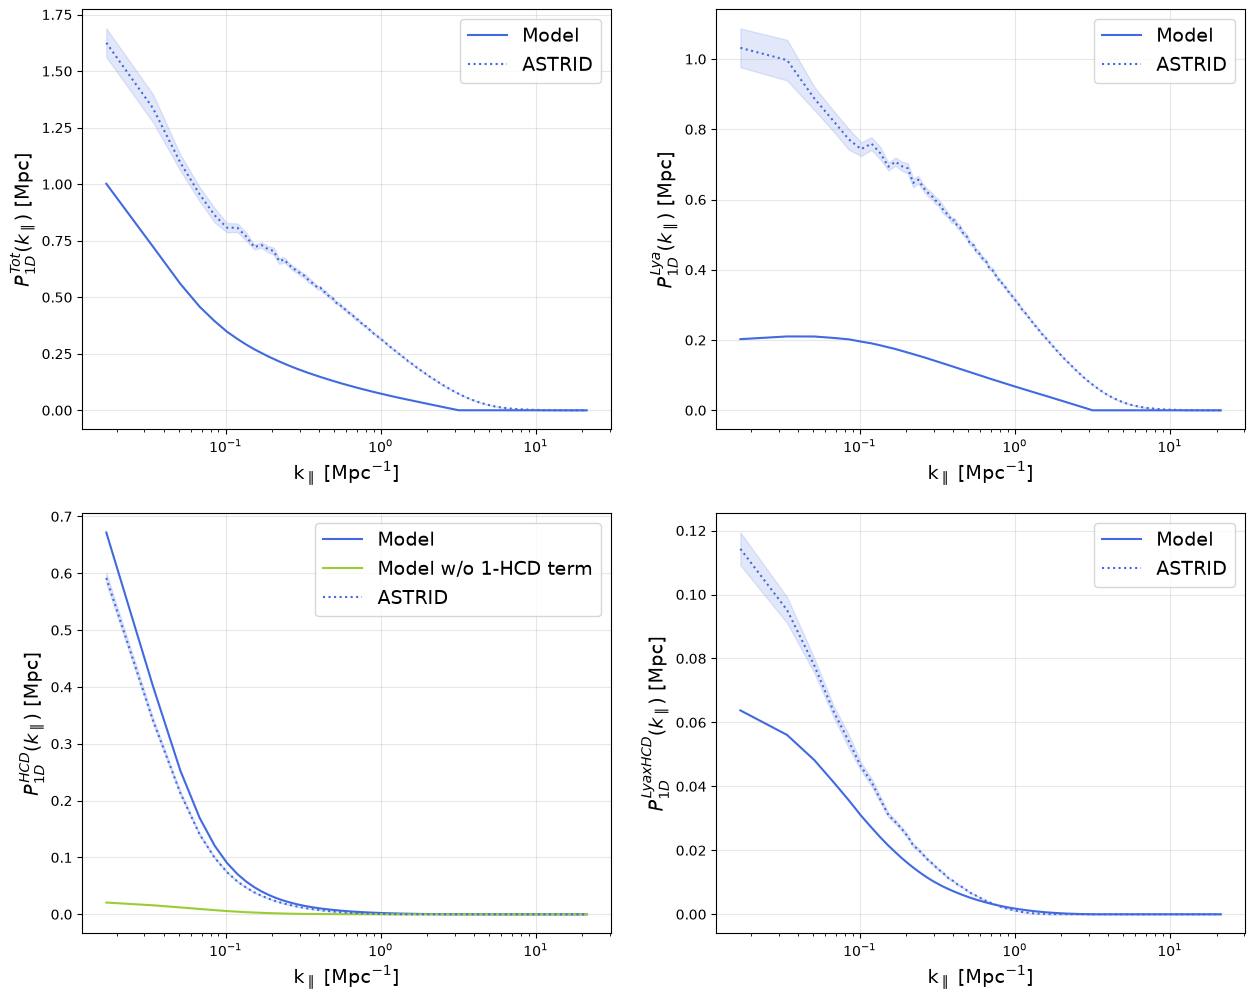

In [11]:
plt.figure(figsize=(15, 12))

plt.subplot(2, 2, 1)
plt.plot(k_los, p1d_tot_m, color='royalblue', label='Model')
plt.plot(k_los, P1d_tot, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_tot-P1d_std_tot), (P1d_tot+P1d_std_tot), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{Tot}(k_\parallel)$ [Mpc]', fontsize=14)


plt.subplot(2, 2, 2)
plt.plot(k_los, p1d_lya_m, color='royalblue', label='Model')
plt.plot(k_los, P1d_lya, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_lya-P1d_std_lya), (P1d_lya+P1d_std_lya), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{Lya}(k_\parallel)$ [Mpc]', fontsize=14)


plt.subplot(2, 2, 3)
plt.plot(k_los, p1d_hcd_m, color='royalblue', label='Model')
plt.plot(k_los, p1d_hcd_m-w1_m, color='yellowgreen', label='Model w/o 1-HCD term')
plt.plot(k_los, P1d_hcd, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_hcd-P1d_std_hcd), (P1d_hcd+P1d_std_hcd), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
#plt.xlim(k_los[1:].min(), 6)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)


plt.subplot(2, 2, 4)
plt.plot(k_los, p1d_lyahcd_m, color='royalblue', label='Model')
plt.plot(k_los, P1d_lyahcd, color='royalblue', linestyle=':', label='ASTRID')
plt.fill_between(k_los, (P1d_lyahcd-P1d_std_lyahcd), (P1d_lyahcd+P1d_std_lyahcd), color='royalblue', alpha=0.15)

plt.legend(loc='upper right', fontsize=14)
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
plt.ylabel(r'$P_{1D}^{LyaxHCD}(k_\parallel)$ [Mpc]', fontsize=14)

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

In [12]:
res_tot = np.abs(P1d_tot - p1d_tot_m)/p1d_tot_m
res_lya = np.abs(P1d_lya - p1d_lya_m)/p1d_lya_m
res_hcd = np.abs(P1d_hcd - p1d_hcd_m)/p1d_hcd_m
res_lyahcd = np.abs(P1d_lyahcd - p1d_lyahcd_m)/p1d_lyahcd_m

/tmp/ipykernel_280/3742198868.py:1: RuntimeWarning: divide by zero encountered in divide
  res_tot = np.abs(P1d_tot - p1d_tot_m)/p1d_tot_m
/tmp/ipykernel_280/3742198868.py:2: RuntimeWarning: divide by zero encountered in divide
  res_lya = np.abs(P1d_lya - p1d_lya_m)/p1d_lya_m
/tmp/ipykernel_280/3742198868.py:3: RuntimeWarning: divide by zero encountered in divide
  res_hcd = np.abs(P1d_hcd - p1d_hcd_m)/p1d_hcd_m
/tmp/ipykernel_280/3742198868.py:4: RuntimeWarning: divide by zero encountered in divide
  res_lyahcd = np.abs(P1d_lyahcd - p1d_lyahcd_m)/p1d_lyahcd_m


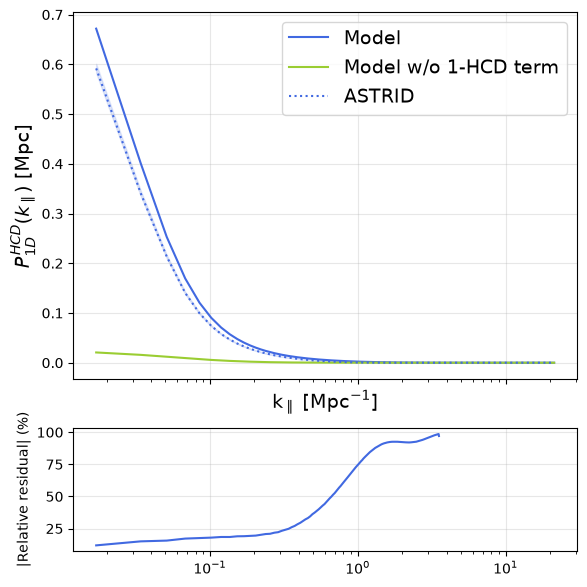

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(6.5, 7), sharex='col',
                         gridspec_kw={'height_ratios': [3, 1]}, )

# Upper panel
ax = axes[0]
ax.plot(k_los, p1d_hcd_m, color='royalblue', label='Model')
ax.plot(k_los, p1d_hcd_m-w1_m, color='yellowgreen', label='Model w/o 1-HCD term')
ax.plot(k_los, P1d_hcd, color='royalblue', linestyle=':', label='ASTRID')
ax.fill_between(k_los, (P1d_hcd-P1d_std_hcd), (P1d_hcd+P1d_std_hcd), color='royalblue', alpha=0.15)

ax.legend(loc='upper right', fontsize=14)
ax.set_xscale('log')
ax.grid(alpha=0.3)
ax.set_xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
ax.set_ylabel(r'$P_{1D}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)

# Lower pannel
ax = axes[1]
ax.plot(k_los, np.abs(res_hcd)*100, color='royalblue')
ax.set_ylabel('|Relative residual| (%)')
ax.grid(alpha=0.3)

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

# Px

In [15]:
r_bins = [0.6, 1.09, 1.97, 3.58, 6.5, 11.8]  # Mpc 
results_px = px_model(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX, r_bins)
k_los_m = results_px['k_los']
px_tot = results_px['px_tot']
px_lya = results_px['px_lya']
px_hcd = results_px['px_hcd']
px_lyahcd = results_px['px_lyahcd']

HCD contribution computed
Lya contribution computed
LyaxHCD contribution computed


In [17]:
data = '/data/desi/scratch/lfloresl/astrid_hcd_outputs/pxs_0.3_21.3_fullbox.hdf5'

with h5py.File(data, 'r') as f:
    print('Atributes:')
    for m in f.attrs.keys():
        print(f'{m} = {f.attrs[m]}')
    logNHI_min = f.attrs['logNHI_min']
    logNHI_max = f.attrs['logNHI_max']
    Lbox = f.attrs['box_size_Mpch']
    Lmbox = f.attrs['minibox_size_Mpch']
    print('----------------') 
    print('Data:')
    print(f.keys())
    k_los = f['k_los'][1:]
    print('k_los shape:', k_los.shape)
    Px_tot = f['px_tot'][0, :, 1:]
    print('px_tot shape:', Px_tot.shape)
    Px_lya = f['px_lya'][0, :, 1:]
    print('px_lya shape:', Px_lya.shape)
    Px_hcd = f['px_hcd'][0, :, 1:]
    print('px_hcd shape:', Px_hcd.shape)
    Px_lyahcd = f['px_lyahcd'][0, :, 1:]
    print('px_lyahcd shape:', Px_lyahcd.shape)
    C = f['C'][()]
    print('Cs shape = ', Cs.shape)
    rbins = f['r_bins'][:]

Atributes:
----- WARNING ----- = Units in terms of h
Smoothing factor = 0.3
box_size_Mpch = 250
logNHI_max = 21.3
logNHI_min = 0
minibox_size_Mpch = 250.0
pixel_width_Mpch = 0.1
pixels_per_skewer = 2500
skewer_separation_Mpch = 0.5
skewers_per_side = 500
----------------
Data:
<KeysViewHDF5 ['C', 'Mask', 'k_los', 'px_3hcd', 'px_3lya', 'px_4', 'px_hcd', 'px_lya', 'px_lyahcd', 'px_tot', 'r_bins']>
k_los shape: (309,)
px_tot shape: (5, 309)
px_lya shape: (5, 309)
px_hcd shape: (5, 309)
px_lyahcd shape: (5, 309)
Cs shape =  (25,)


In [18]:
k_los *= cosmo.CAMBparams.h  # In Mpc^-1
rbins /= cosmo.CAMBparams.h  # In Mpc
Px_tot /= cosmo.CAMBparams.h
Px_lya /= cosmo.CAMBparams.h 
Px_hcd /= cosmo.CAMBparams.h 
Px_lyahcd /= cosmo.CAMBparams.h 

px_tot_m, px_lya_m, px_hcd_m , px_lyahcd_m = [], [], [], []
for i in np.arange(px_tot.shape[0]):
    px_tot_m.append(np.interp(k_los, k_los_m, px_tot[i, 0, :]))
    px_lya_m.append(np.interp(k_los, k_los_m, px_lya[i, 0, :]))
    px_hcd_m.append(np.interp(k_los, k_los_m, px_hcd[i, 0, :]))
    px_lyahcd_m.append(np.interp(k_los, k_los_m, px_lyahcd[i, 0, :]))
px_tot_m, px_lya_m, px_hcd_m, px_lyahcd_m = np.array(px_tot_m), np.array(px_lya_m), np.array(px_hcd_m) , np.array(px_lyahcd_m)

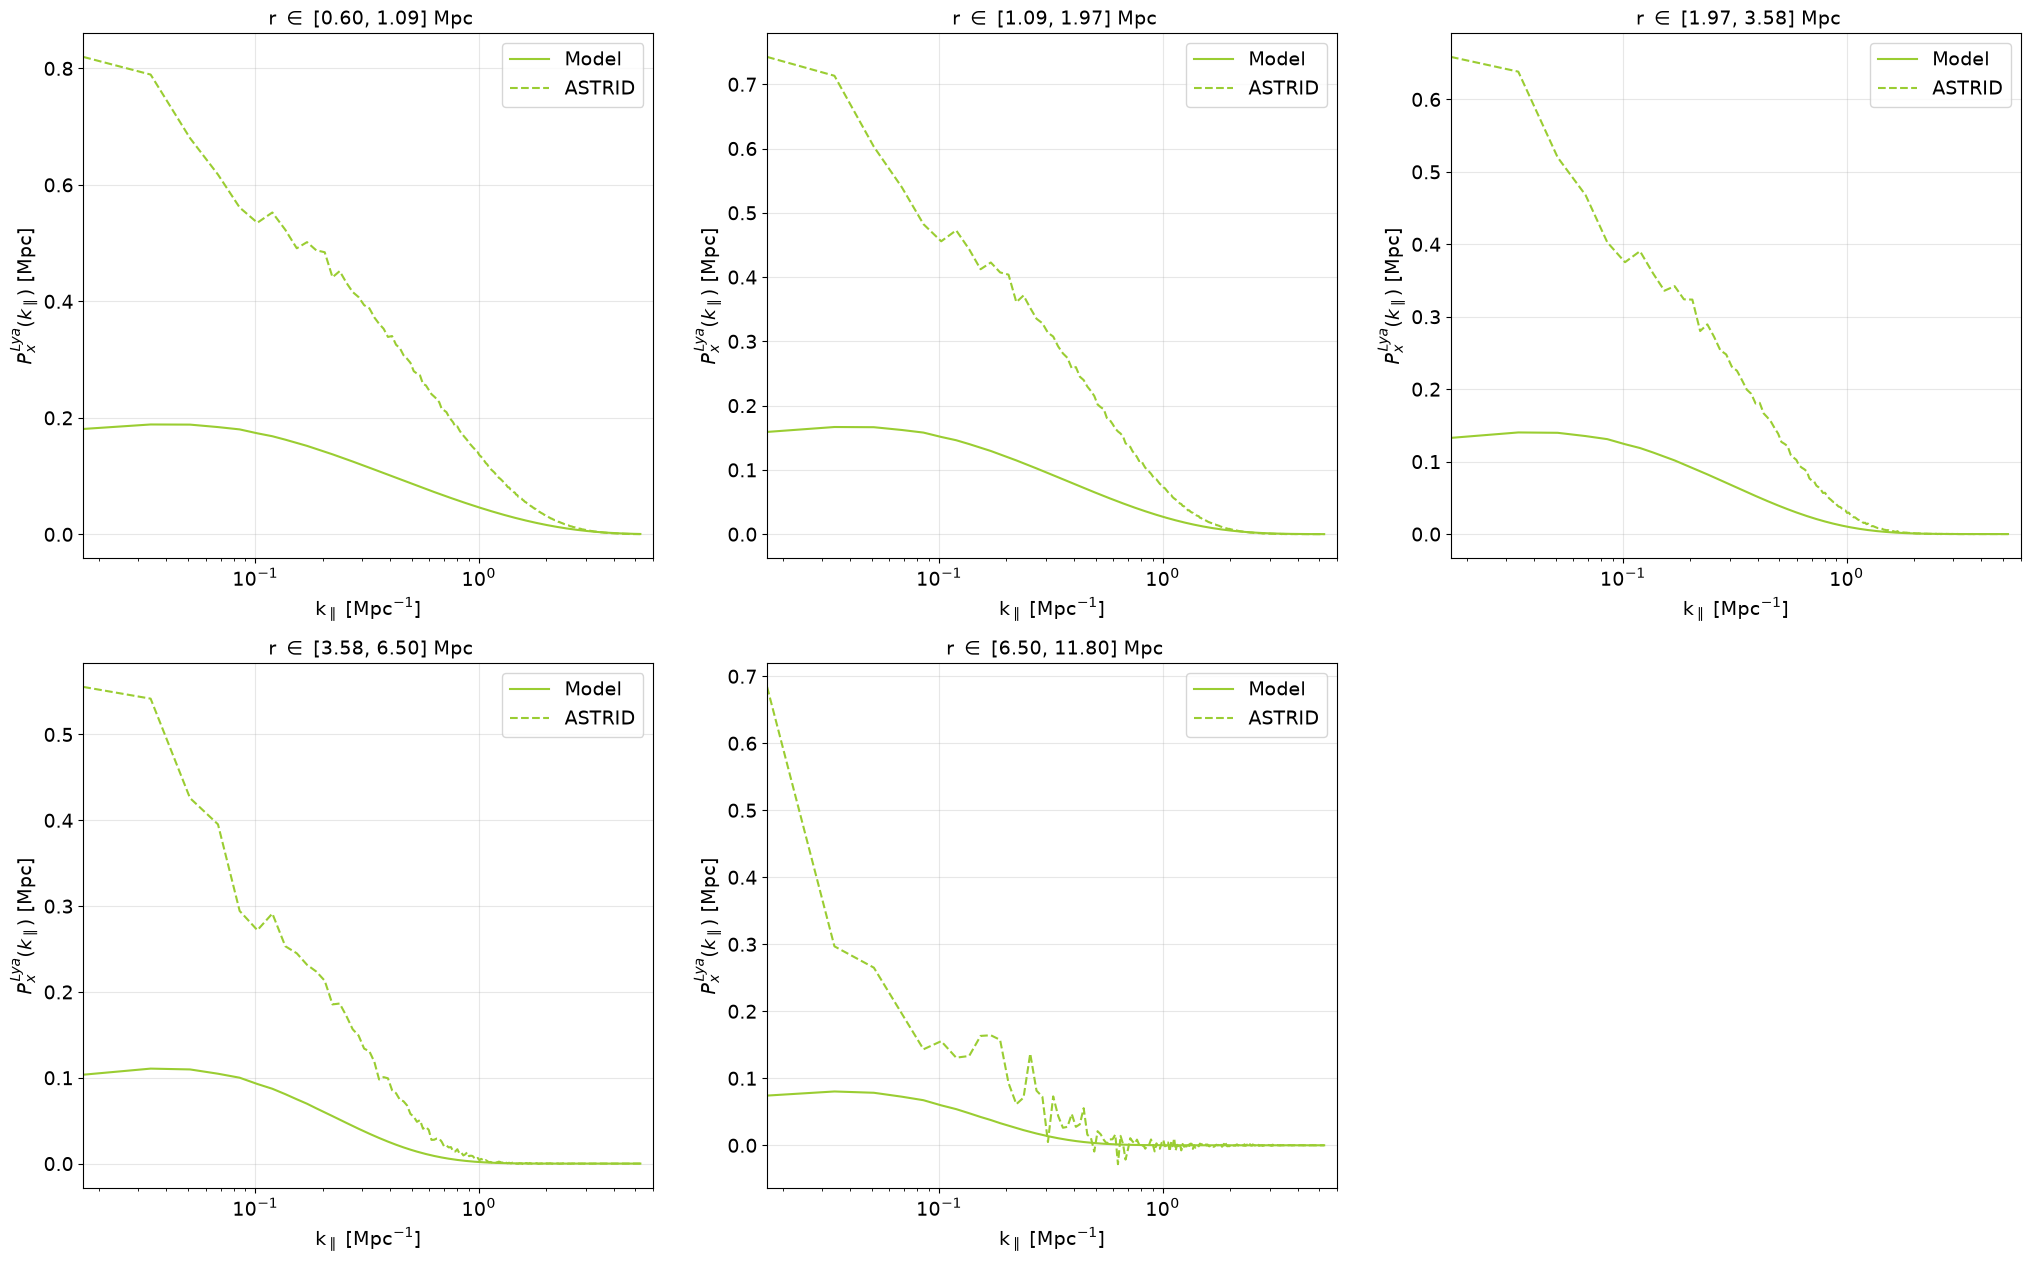

In [19]:
plt.figure(figsize=(25, 15))

for i in np.arange(len(r_bins)-1):
    plt.subplot(2, 3, i+1)
    plt.plot(k_los, px_lya_m[i, :], color='yellowgreen', label='Model')
    plt.plot(k_los, Px_lya[i, :], color='yellowgreen', linestyle='--', label='ASTRID')
    plt.legend(loc='upper right', fontsize=14)

    plt.xscale('log')
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(alpha=0.3)
    plt.xlim(k_los.min(), 6)
    plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
    plt.ylabel(r'$P_{x}^{Lya}(k_\parallel)$ [Mpc]', fontsize=14)
    plt.title(f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]), fontsize=14);

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

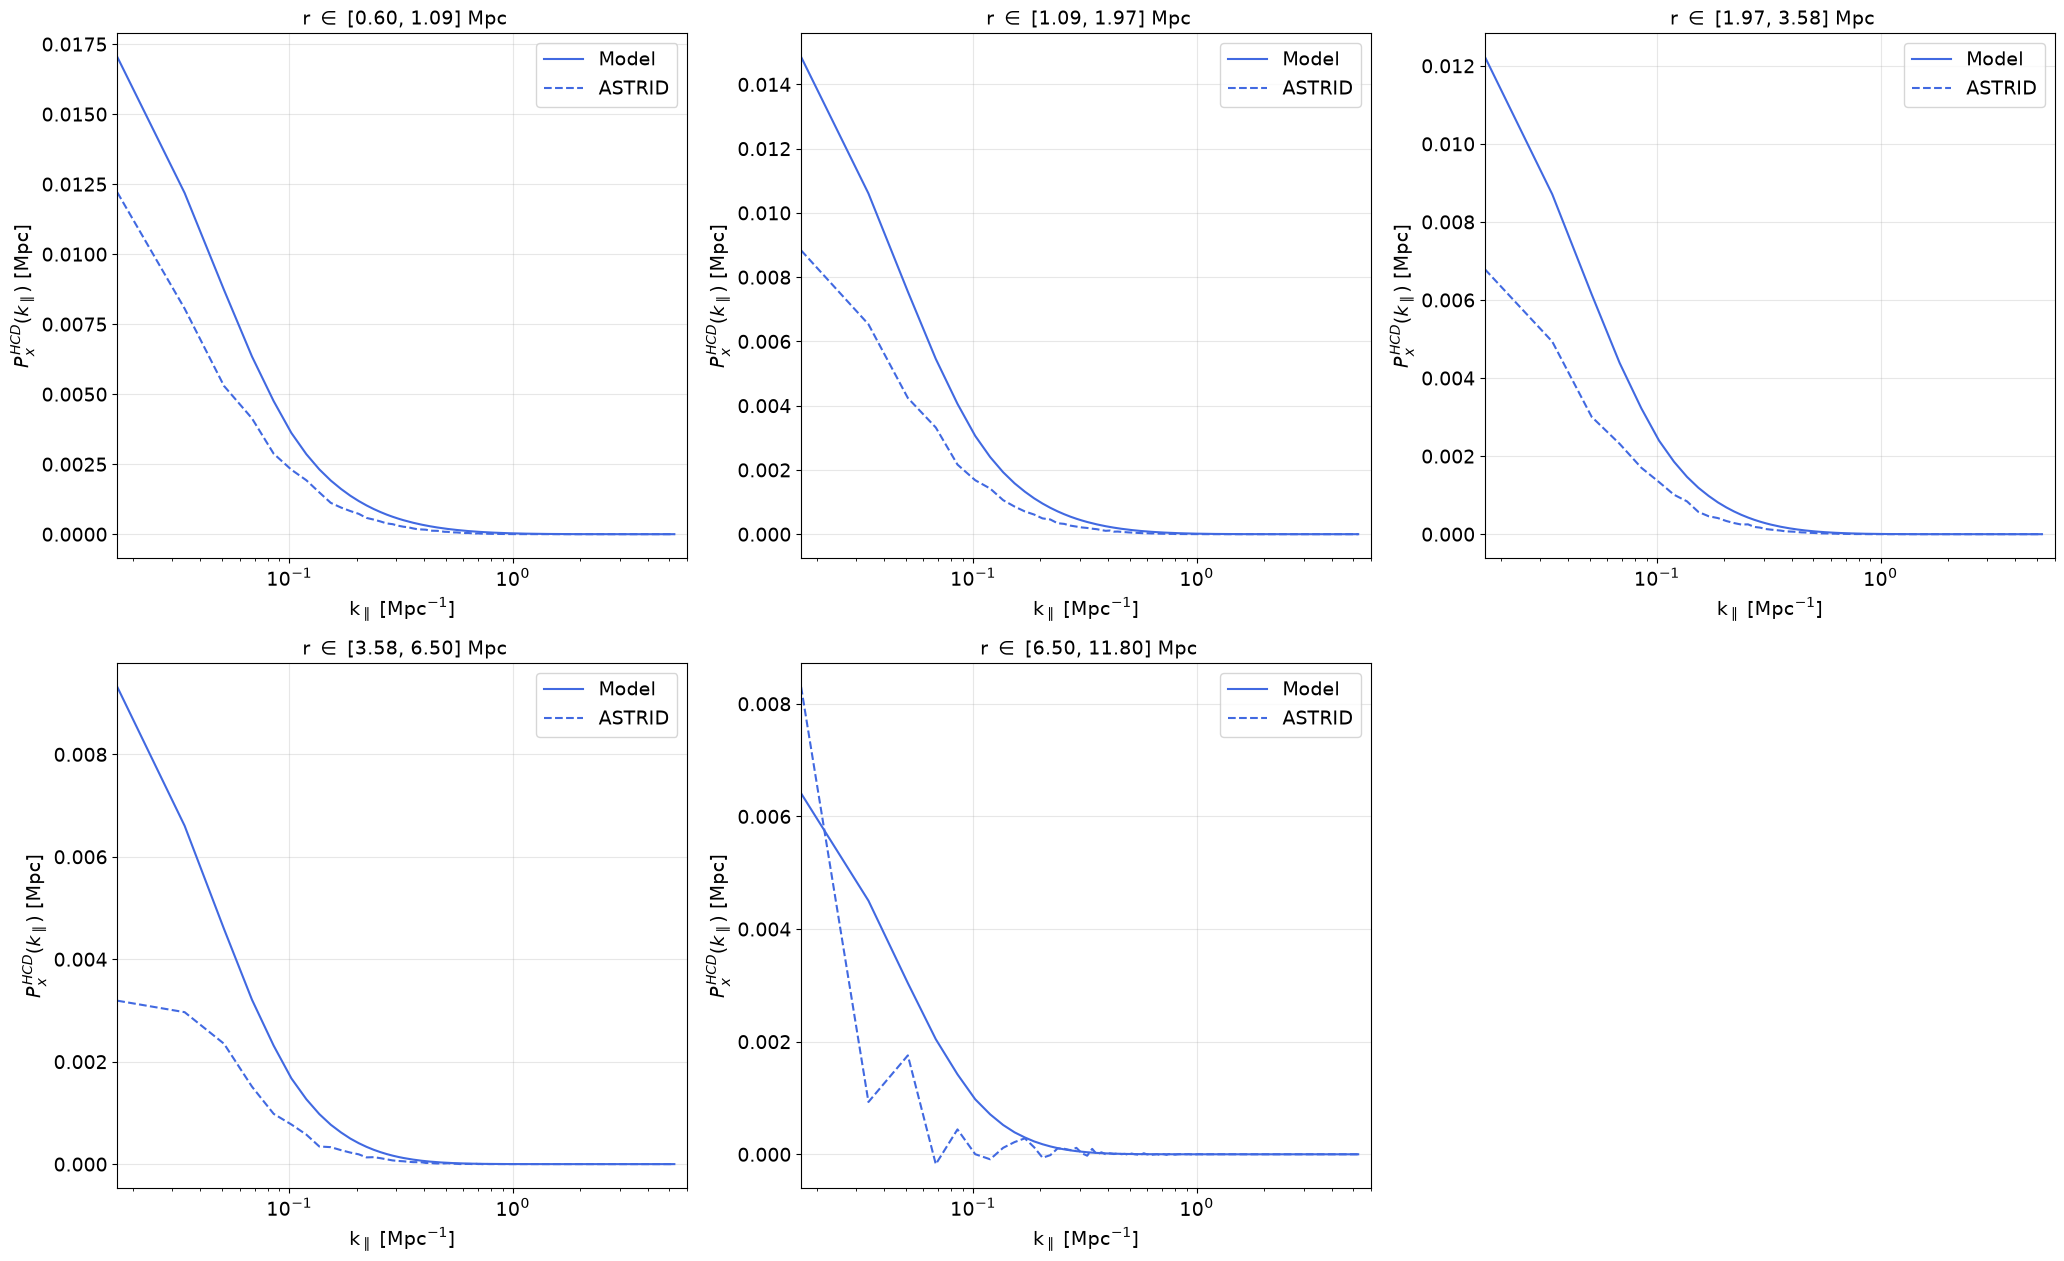

In [20]:
plt.figure(figsize=(25, 15))

for i in np.arange(len(r_bins)-1):
    plt.subplot(2, 3, i+1)
    plt.plot(k_los, px_hcd_m[i, :], color='royalblue', label='Model')
    plt.plot(k_los, Px_hcd[i, :], color='royalblue', linestyle='--', label='ASTRID')

    plt.legend(loc='upper right', fontsize=14)

    plt.xscale('log')
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(alpha=0.3)
    plt.xlim(k_los.min(), 6)
    plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
    plt.ylabel(r'$P_{x}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)
    plt.title(f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]), fontsize=14);

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

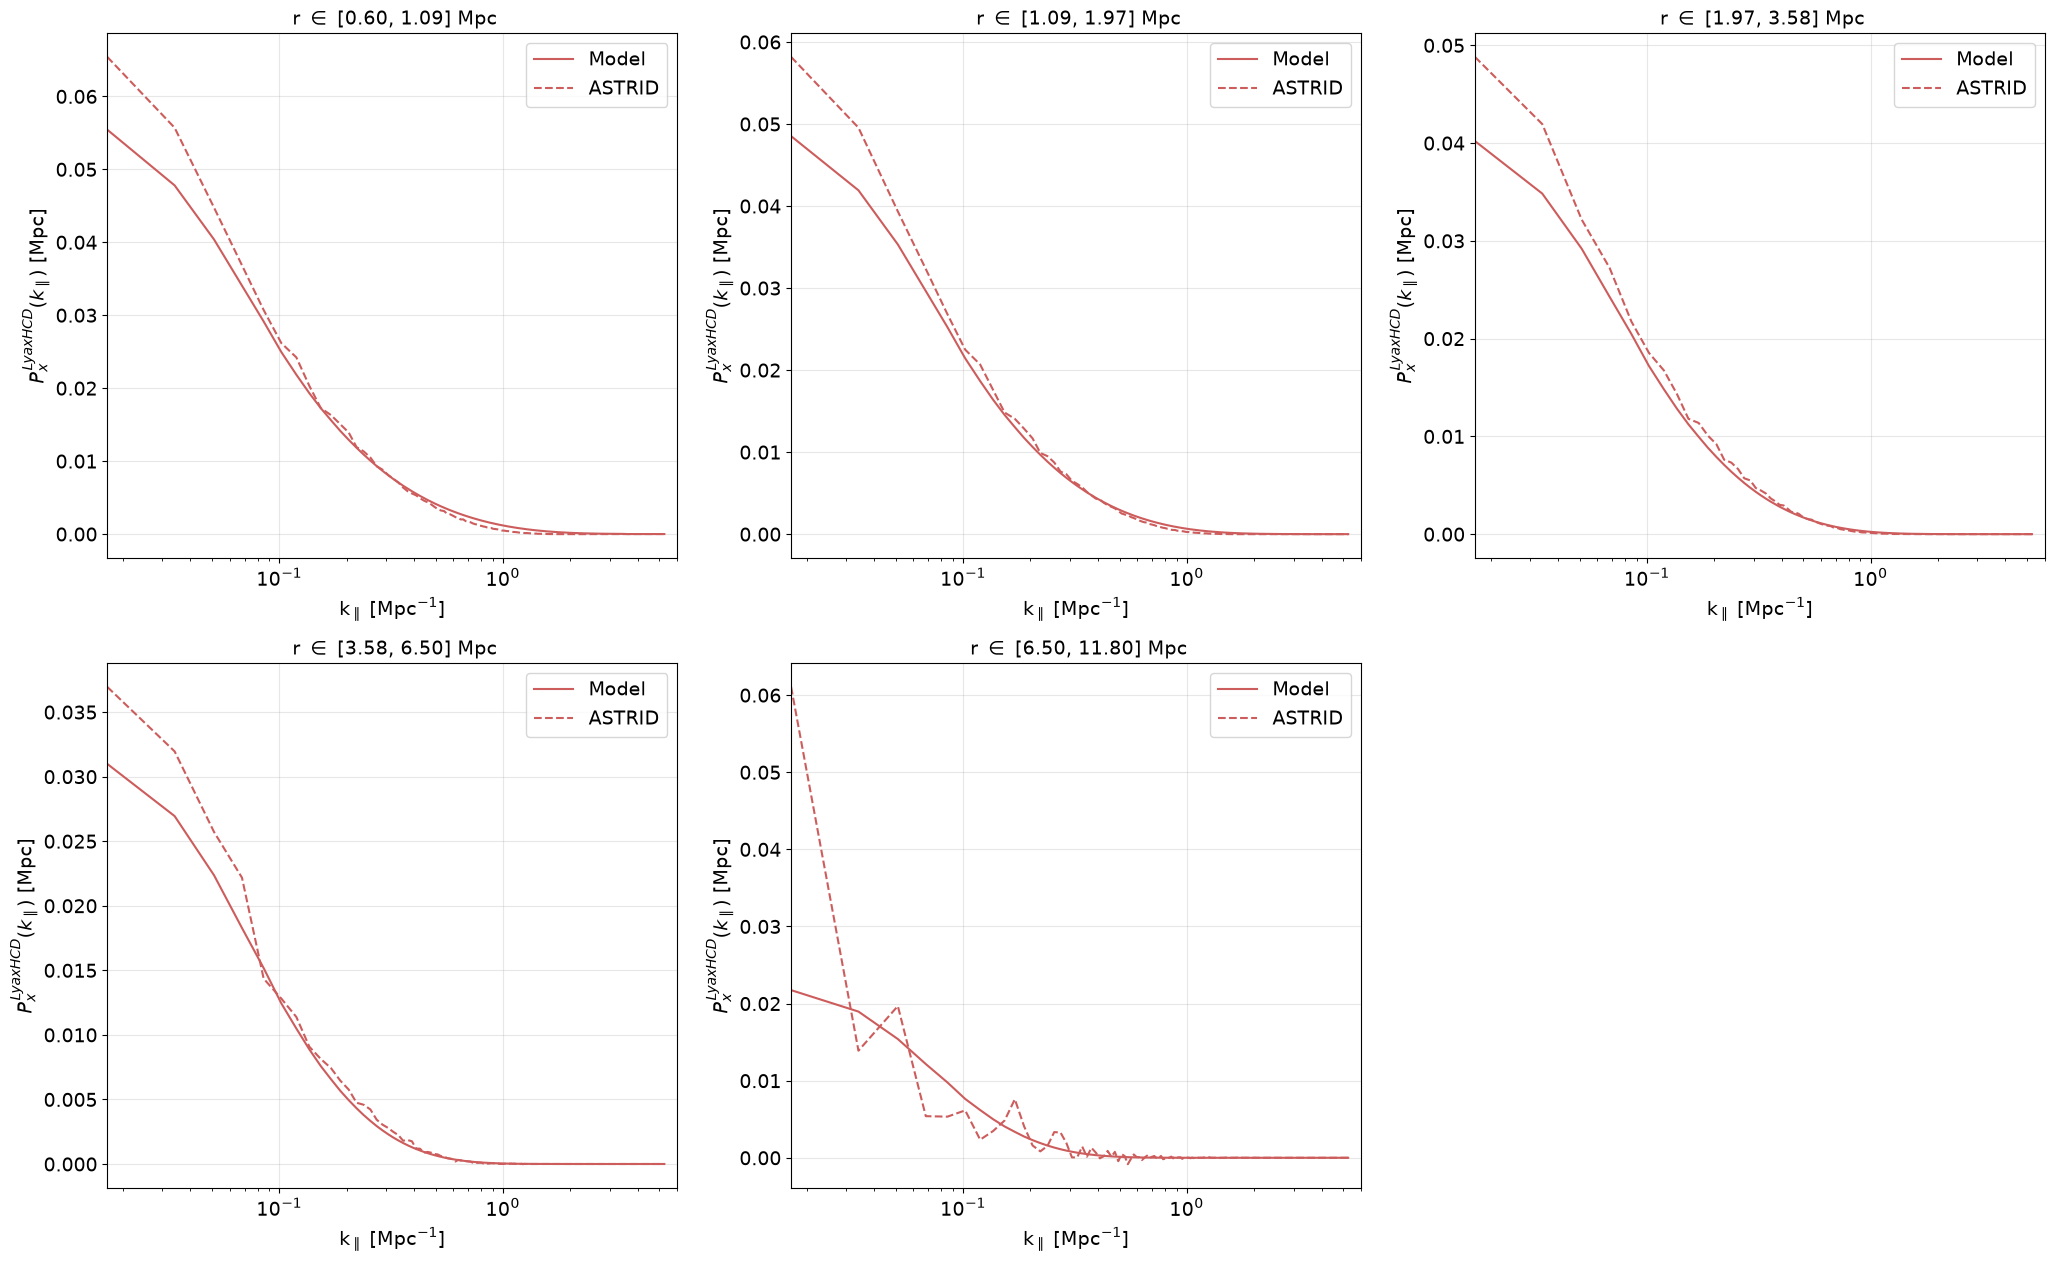

In [21]:
plt.figure(figsize=(25, 15))

for i in np.arange(len(r_bins)-1):
    plt.subplot(2, 3, i+1)
    plt.plot(k_los, px_lyahcd_m[i, :], color='indianred', label='Model')
    plt.plot(k_los, Px_lyahcd[i, :], color='indianred', linestyle='--', label='ASTRID')
    plt.legend(loc='upper right', fontsize=14)

    plt.xscale('log')
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(alpha=0.3)
    plt.xlim(k_los.min(), 6)
    plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
    plt.ylabel(r'$P_{x}^{LyaxHCD}(k_\parallel)$ [Mpc]', fontsize=14)
    plt.title(f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]), fontsize=14);

plt.savefig('plot.png', dpi=200, bbox_inches='tight')

In [22]:
res_tot = np.abs(Px_tot - px_tot_m)/px_tot_m
res_lya = np.abs(Px_lya - px_lya_m)/px_lya_m
res_hcd = np.abs(Px_hcd - px_hcd_m)/px_hcd_m
res_lyahcd = np.abs(Px_lyahcd - px_lyahcd_m)/px_lyahcd_m

/tmp/ipykernel_280/1605043236.py:3: RuntimeWarning: divide by zero encountered in divide
  res_hcd = np.abs(Px_hcd - px_hcd_m)/px_hcd_m
/tmp/ipykernel_280/1605043236.py:4: RuntimeWarning: divide by zero encountered in divide
  res_lyahcd = np.abs(Px_lyahcd - px_lyahcd_m)/px_lyahcd_m


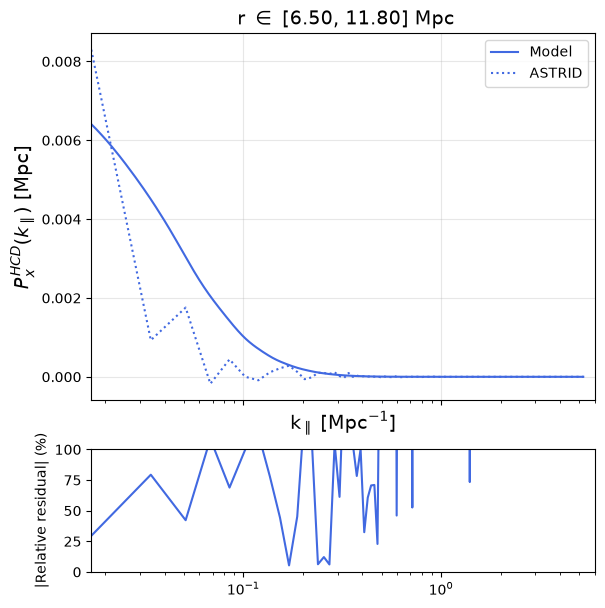

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(6.5, 7), sharex='col',
                         gridspec_kw={'height_ratios': [3, 1]}, )

i = 4
# Upper panel
ax = axes[0]
ax.plot(k_los_m, px_hcd[i, 0, :], color='royalblue', label='Model')
ax.plot(k_los, Px_hcd[i, :], color='royalblue', linestyle=':', label='ASTRID')

ax.legend(loc='upper right')
ax.set_xscale('log')
ax.grid(alpha=0.3)
ax.set_xlim(k_los.min(), 6)
ax.set_xlabel(r'k$_\parallel$ [Mpc$^{-1}$]', fontsize=14)
ax.set_ylabel(r'$P_{x}^{HCD}(k_\parallel)$ [Mpc]', fontsize=14)
ax.set_title(f' r $\\in$ [%.2f, %.2f] Mpc' %(r_bins[i], r_bins[i+1]), fontsize=14)

# Lower pannel
ax = axes[1]
ax.plot(k_los, np.abs(res_hcd[i, :])*100, color='royalblue')
ax.set_ylabel('|Relative residual| (%)')
ax.set_ylim(0, 100);

plt.savefig('plot.png', dpi=200, bbox_inches='tight')